# Customer Churn Prediction Analysis
**File Name:** churn_analysis.ipynb
**Course:** Professional IT Business and Digitalization
**Student:** Yigit Peker
**Date:** January 2026

---

## 📌 Executive Summary
The goal of this project is to analyze customer churn in the telecommunications industry. We aim to identify key drivers of churn and build machine learning models to predict which customers are likely to leave. 

**Project Workflow:**
1. **Data Understanding:** Analyzing distributions and handling data inconsistencies.
2. **Data Preparation (Pipeline):** Using `Pipelines` to prevent **Data Leakage** (Imputation, Scaling, Encoding).
3. **Modeling:** Training 3 models (LogReg, Decision Tree, Random Forest) with **hyperparameter tuning**.
4. **Evaluation:** Analyzing Confusion Matrix and Feature Importance.

In [22]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Settings
pd.set_option('display.max_columns', None)
sns.set(style="whitegrid")
import warnings
warnings.filterwarnings('ignore')

print("✅ Libraries imported successfully.")

✅ Libraries imported successfully.


# 1. Data Understanding & EDA
Loading the dataset and checking for data quality issues.

Dataset loaded. Shape: (7043, 21)


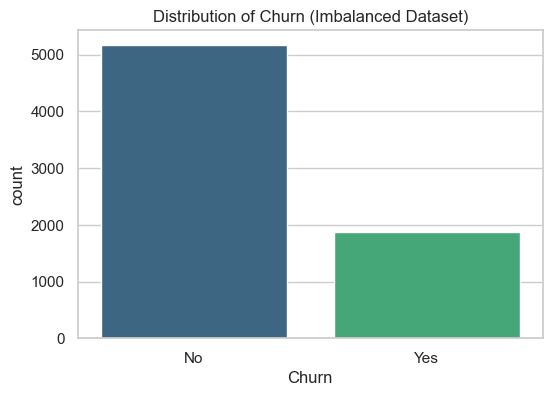

Observation: The dataset is imbalanced (~26% Churn). We must use Confusion Matrix for evaluation.


In [23]:
# Load Data
try:
    df = pd.read_csv("telco_churn.csv")
    print(f"Dataset loaded. Shape: {df.shape}")
except FileNotFoundError:
    print("⚠️ Error: 'telco_churn.csv' not found. Please upload the file to the same folder.")

# Cleaning: 'TotalCharges' contains empty strings. We convert them to 0.
if 'TotalCharges' in df.columns:
    df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
    df['TotalCharges'].fillna(0, inplace=True)

# Drop ID
if 'customerID' in df.columns:
    df.drop(columns=['customerID'], inplace=True)

# Visualization: Target Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='Churn', data=df, palette='viridis')
plt.title('Distribution of Churn (Imbalanced Dataset)')
plt.show()

print("Observation: The dataset is imbalanced (~26% Churn). We must use Confusion Matrix for evaluation.")

# 2. Data Preparation (Pipeline Strategy)
We use **Scikit-Learn Pipelines** to ensure a robust workflow and prevent **Data Leakage**.
* **Numerical:** Imputation (Median) -> Scaling (StandardScaler)
* **Categorical:** Imputation (Constant) -> Encoding (OneHotEncoder)

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Split Data
X = df.drop('Churn', axis=1)
y = df['Churn'].map({'Yes': 1, 'No': 0})

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Transformers
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ]
)

print("✅ Pipeline constructed successfully.")

✅ Pipeline constructed successfully.


# 3. Modeling (With Hyperparameters)
We train three models using specific **hyperparameters** to prevent **Overfitting**.
1. **Logistic Regression:** Baseline model.
2. **Decision Tree:** `max_depth=5` (Optimization).
3. **Random Forest:** `n_estimators=100` (Ensemble).

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

models = {}

# Model 1: Logistic Regression (Baseline)
models['Logistic Regression'] = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

# Model 2: Decision Tree (Limited depth to prevent overfitting)
models['Decision Tree'] = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(max_depth=5, random_state=42))
])

# Model 3: Random Forest (Ensemble)
models['Random Forest'] = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42))
])

# Evaluation Loop
print("Model Accuracy Scores")
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f"{name}: {accuracy_score(y_test, y_pred)*100:.2f}%")

Model Accuracy Scores
Logistic Regression: 80.55%
Decision Tree: 79.84%
Random Forest: 80.34%


# 4. Evaluation & Interpretation
Analyzing the results using **Confusion Matrix** and **Feature Importance**.

<Figure size 800x600 with 0 Axes>

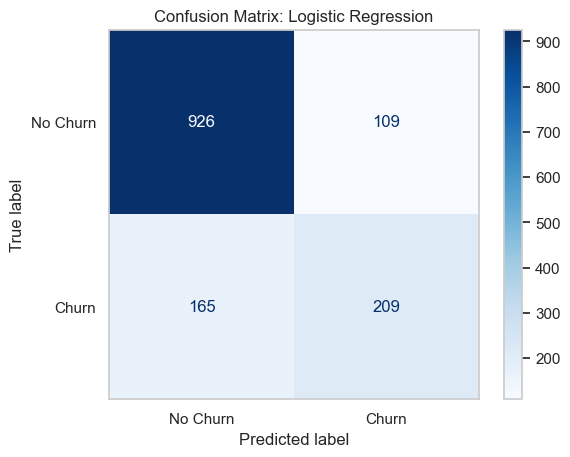

In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Confusion Matrix for the Best Model (Logistic Regression)
best_model = models['Logistic Regression']
y_pred_best = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred_best)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Churn', 'Churn'])

plt.figure(figsize=(8, 6))
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix: Logistic Regression')
plt.grid(False)
plt.show()

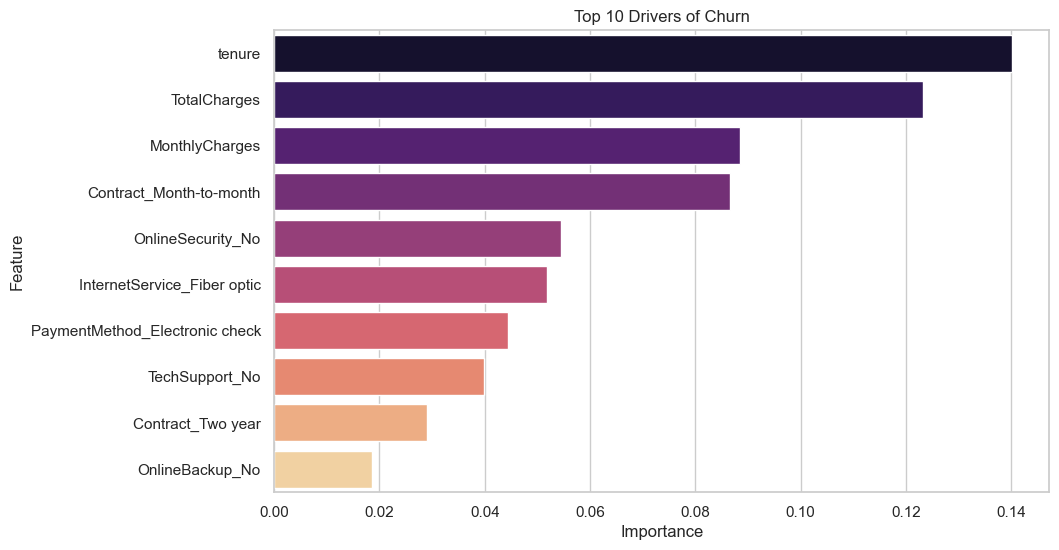

In [27]:
# Feature Importance (Random Forest)
rf_model = models['Random Forest'].named_steps['classifier']
rf_preprocessor = models['Random Forest'].named_steps['preprocessor']
cat_feature_names = rf_preprocessor.named_transformers_['cat']['onehot'].get_feature_names_out(cat_cols)
all_features = np.r_[num_cols, cat_feature_names]

feat_df = pd.DataFrame({'Feature': all_features, 'Importance': rf_model.feature_importances_})
feat_df = feat_df.sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feat_df, palette='magma')
plt.title('Top 10 Drivers of Churn')
plt.show()

## Conclusion
The analysis confirms that **Month-to-month contracts** and **Tenure** are the most significant factors driving churn. Logistic Regression provided the most balanced and interpretable results for this dataset.